In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "mrpc"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 3668
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'Amrozi accused his brother , whom he called " the witness " , of deliberately distorting his evidence .',
 'sentence2': 'Referring to him as only " the witness " , Amrozi accused his brother of deliberately distorting his evidence .',
 'label': 1,
 'idx': 0}

In [10]:
raw_train_dataset[5]['sentence1'], raw_train_dataset[5]['sentence2']

('Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .',
 "With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .")

In [11]:
raw_train_dataset[5]['label']

1

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['not_equivalent', 'equivalent']),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 100]),
 'token_type_ids': torch.Size([32, 100]),
 'attention_mask': torch.Size([32, 100])}

# 4. Load Model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(1.2996, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [25]:
outputs.keys()

odict_keys(['loss', 'logits', 'hidden_states', 'attentions'])

In [26]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

In [27]:
len(outputs.hidden_states['hidden_states']), outputs.hidden_states['hidden_states'][0].shape

(13, torch.Size([32, 100, 768]))

In [28]:
len(outputs.attentions['attention_head'])

12

In [29]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 100, 100])

In [30]:
len(outputs.attentions["pre_wo"])

12

In [31]:
outputs.attentions["pre_wo"][0].shape

torch.Size([32, 100, 768])

In [32]:
outputs.attentions["attention_output"][0].shape

torch.Size([32, 100, 768])

### Loading Trained Weights

In [33]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [34]:
from train_eval_func import eval_loop

In [35]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.8676470588235294, 'f1': 0.9093959731543624}

# 5. Similarity Analysis

In [36]:
from CKA import CKAEvaluator

cka_eval = CKAEvaluator(device)

In [37]:
from CKA import SentenceCKARedundancy

headsCka_eval = SentenceCKARedundancy(device)

In [38]:
def adjacent_similarity_stats(
    similarity_scores, 
    thresold = 0.80,
    disp_sim_score=True, 
    disp_group_count=True
):
    adj_similarities = []
    for i in range(1, len(similarity_scores)):
        adj_similarities.append(similarity_scores[i-1][i])

    if disp_sim_score:
        print("Similarity Scores:", adj_similarities)

    high_pair_count = 0
    for pair in adj_similarities:
        if pair > thresold:
            high_pair_count += 1
    
    if disp_group_count:
        print("Number of High Similar Pairs:", high_pair_count)

    return adj_similarities, high_pair_count

### Using Training Data on CLS Token only

In [32]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:23<00:00,  1.38it/s]

  Reps Similarity Stats:
    Average: 0.899587
    Highest: 0.993594
    Lowest:  0.723103

  Atts Similarity Stats:
    Average: 0.944064
    Highest: 0.991232
    Lowest:  0.760821
  MHA Similarity Stats:
    Average: 0.916322
    Highest: 0.988968
    Lowest:  0.809322
  Pre Wo Similarity Stats:
    Average: 0.828560
    Highest: 0.946645
    Lowest:  0.644238
  Sublayer Similarity Stats:
    Average: 0.948331
    Highest: 0.996554
    Lowest:  0.788115
  Pre Wo Sublayer Similarity Stats:
    Average: 0.880918
    Highest: 0.974673
    Lowest:  0.706310


In [33]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:59<00:00,  1.93it/s]

  Sub Out Similarity Stats:
    Average: 0.904148
    Highest: 0.994790
    Lowest:  0.616531


In [34]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

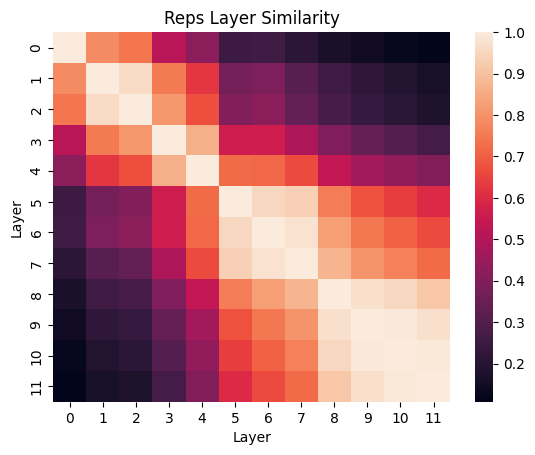

In [42]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [43]:
_,_ = adjacent_similarity_stats(reps_similarity)

Similarity Scores: [0.7847003, 0.9596504, 0.80496854, 0.8608353, 0.7231031, 0.95301914, 0.9779881, 0.87349385, 0.9742549, 0.99359417, 0.9898457]
Number of High Similar Pairs: 9


In [44]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.85)

Similarity Scores: [0.7847003, 0.9596504, 0.80496854, 0.8608353, 0.7231031, 0.95301914, 0.9779881, 0.87349385, 0.9742549, 0.99359417, 0.9898457]
Number of High Similar Pairs: 8


In [45]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.9)

Similarity Scores: [0.7847003, 0.9596504, 0.80496854, 0.8608353, 0.7231031, 0.95301914, 0.9779881, 0.87349385, 0.9742549, 0.99359417, 0.9898457]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

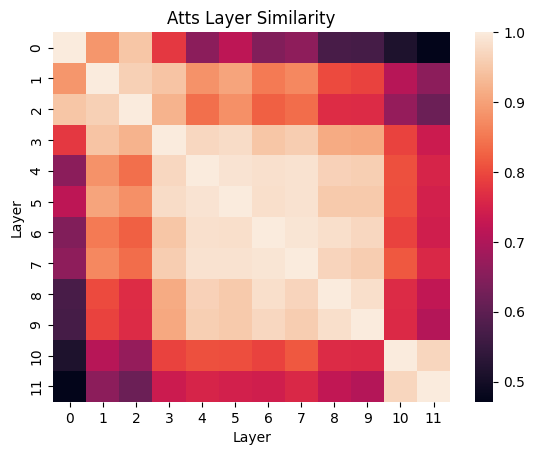

In [39]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [40]:
_,_ = adjacent_similarity_stats(atts_similarity)

Similarity Scores: [0.88554806, 0.96219337, 0.9218789, 0.9716704, 0.98803926, 0.9830086, 0.991232, 0.9681887, 0.9815062, 0.76082104, 0.9706123]
Number of High Similar Pairs: 10


In [41]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.85)

Similarity Scores: [0.88554806, 0.96219337, 0.9218789, 0.9716704, 0.98803926, 0.9830086, 0.991232, 0.9681887, 0.9815062, 0.76082104, 0.9706123]
Number of High Similar Pairs: 10


In [42]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.9)

Similarity Scores: [0.88554806, 0.96219337, 0.9218789, 0.9716704, 0.98803926, 0.9830086, 0.991232, 0.9681887, 0.9815062, 0.76082104, 0.9706123]
Number of High Similar Pairs: 9


Text(50.722222222222214, 0.5, 'Layer')

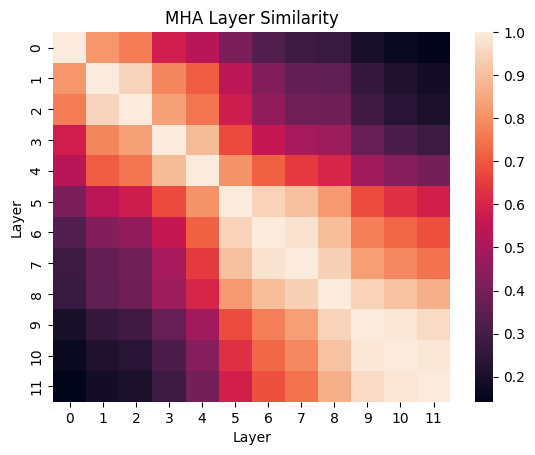

In [43]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [44]:
_,_ = adjacent_similarity_stats(mha_similarity)

Similarity Scores: [0.81448126, 0.9496741, 0.8356534, 0.8896596, 0.8093225, 0.945767, 0.9772608, 0.936403, 0.9456768, 0.9866716, 0.98896784]
Number of High Similar Pairs: 11


In [45]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.85)

Similarity Scores: [0.81448126, 0.9496741, 0.8356534, 0.8896596, 0.8093225, 0.945767, 0.9772608, 0.936403, 0.9456768, 0.9866716, 0.98896784]
Number of High Similar Pairs: 8


In [46]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.9)

Similarity Scores: [0.81448126, 0.9496741, 0.8356534, 0.8896596, 0.8093225, 0.945767, 0.9772608, 0.936403, 0.9456768, 0.9866716, 0.98896784]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

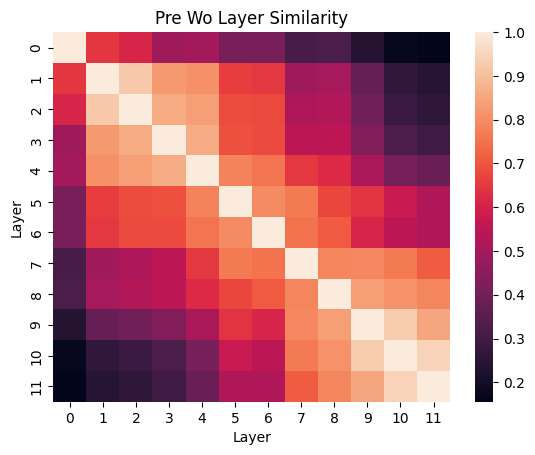

In [47]:
title = "Pre Wo Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [48]:
_,_ = adjacent_similarity_stats(pre_wo_similarity)

Similarity Scores: [0.64423794, 0.92404544, 0.85961324, 0.862082, 0.7801342, 0.7967044, 0.7515198, 0.7868178, 0.83490807, 0.9274497, 0.9466455]
Number of High Similar Pairs: 6


In [49]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.85)

Similarity Scores: [0.64423794, 0.92404544, 0.85961324, 0.862082, 0.7801342, 0.7967044, 0.7515198, 0.7868178, 0.83490807, 0.9274497, 0.9466455]
Number of High Similar Pairs: 5


In [50]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.9)

Similarity Scores: [0.64423794, 0.92404544, 0.85961324, 0.862082, 0.7801342, 0.7967044, 0.7515198, 0.7868178, 0.83490807, 0.9274497, 0.9466455]
Number of High Similar Pairs: 3


Text(50.722222222222214, 0.5, 'Layer')

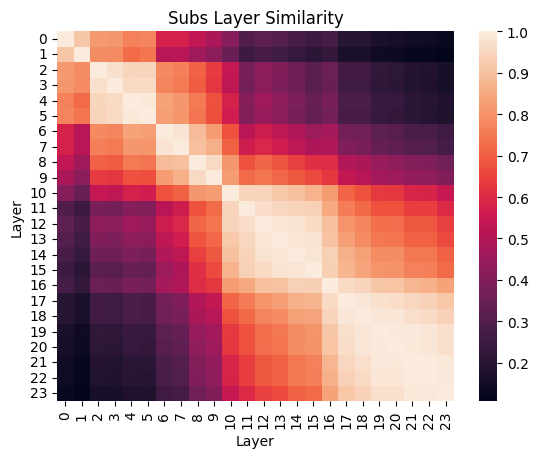

In [51]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [52]:
_,_ = adjacent_similarity_stats(sub_similarity)

Similarity Scores: [0.909702, 0.7881147, 0.9726945, 0.9583757, 0.9917159, 0.82300204, 0.97967553, 0.8984798, 0.95544887, 0.8202438, 0.9464082, 0.9673187, 0.9853821, 0.98315996, 0.98456144, 0.9318756, 0.96139705, 0.98675513, 0.98762923, 0.99597913, 0.9923215, 0.99655426, 0.9948107]
Number of High Similar Pairs: 22


In [53]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.85)

Similarity Scores: [0.909702, 0.7881147, 0.9726945, 0.9583757, 0.9917159, 0.82300204, 0.97967553, 0.8984798, 0.95544887, 0.8202438, 0.9464082, 0.9673187, 0.9853821, 0.98315996, 0.98456144, 0.9318756, 0.96139705, 0.98675513, 0.98762923, 0.99597913, 0.9923215, 0.99655426, 0.9948107]
Number of High Similar Pairs: 20


In [54]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.9)

Similarity Scores: [0.909702, 0.7881147, 0.9726945, 0.9583757, 0.9917159, 0.82300204, 0.97967553, 0.8984798, 0.95544887, 0.8202438, 0.9464082, 0.9673187, 0.9853821, 0.98315996, 0.98456144, 0.9318756, 0.96139705, 0.98675513, 0.98762923, 0.99597913, 0.9923215, 0.99655426, 0.9948107]
Number of High Similar Pairs: 19


Text(50.722222222222214, 0.5, 'Layer')

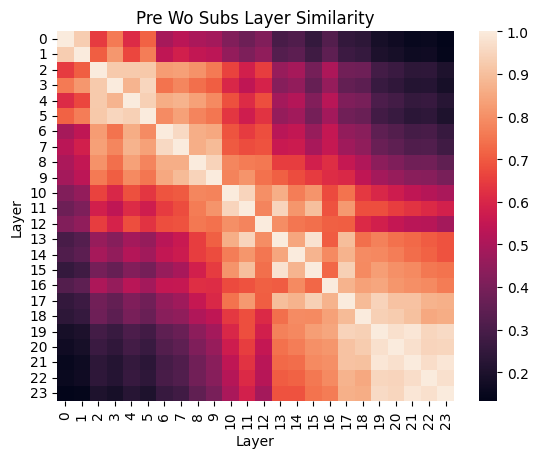

In [55]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [56]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity)

Similarity Scores: [0.92902726, 0.70631003, 0.92539567, 0.8779427, 0.93561864, 0.79206616, 0.9559945, 0.8625771, 0.94319266, 0.77508366, 0.94773334, 0.7784922, 0.7946972, 0.8456423, 0.87746084, 0.7228143, 0.8740291, 0.8900157, 0.9364582, 0.97352123, 0.97361624, 0.96875334, 0.97467333]
Number of High Similar Pairs: 17


In [57]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.92902726, 0.70631003, 0.92539567, 0.8779427, 0.93561864, 0.79206616, 0.9559945, 0.8625771, 0.94319266, 0.77508366, 0.94773334, 0.7784922, 0.7946972, 0.8456423, 0.87746084, 0.7228143, 0.8740291, 0.8900157, 0.9364582, 0.97352123, 0.97361624, 0.96875334, 0.97467333]
Number of High Similar Pairs: 16


In [58]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.92902726, 0.70631003, 0.92539567, 0.8779427, 0.93561864, 0.79206616, 0.9559945, 0.8625771, 0.94319266, 0.77508366, 0.94773334, 0.7784922, 0.7946972, 0.8456423, 0.87746084, 0.7228143, 0.8740291, 0.8900157, 0.9364582, 0.97352123, 0.97361624, 0.96875334, 0.97467333]
Number of High Similar Pairs: 11


Text(50.722222222222214, 0.5, 'Layer')

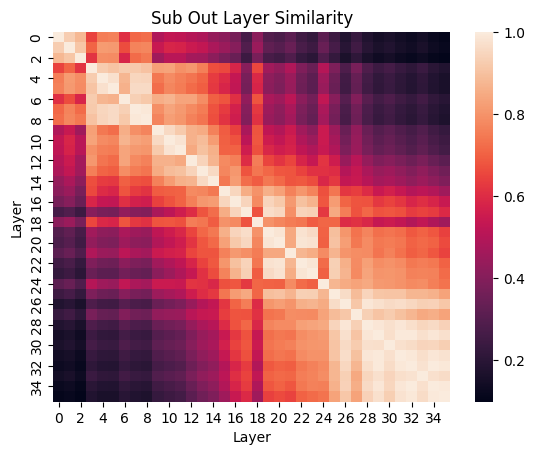

In [35]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [36]:
_,_ = adjacent_similarity_stats(sub_out_similarity)

Similarity Scores: [0.9282248, 0.9097062, 0.6165314, 0.92563117, 0.97278965, 0.8658998, 0.9350111, 0.99166244, 0.7694076, 0.95594126, 0.97967273, 0.8453357, 0.9424543, 0.95549417, 0.74397457, 0.9475094, 0.9467639, 0.6761828, 0.7959965, 0.98507833, 0.8419247, 0.87650025, 0.9846492, 0.69878435, 0.87341136, 0.9615374, 0.9130157, 0.93479997, 0.9875872, 0.9700982, 0.9732967, 0.99238133, 0.9782865, 0.9748429, 0.9947901]
Number of High Similar Pairs: 29


In [37]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.92902726, 0.70631003, 0.92539567, 0.8779427, 0.93561864, 0.79206616, 0.9559945, 0.8625771, 0.94319266, 0.77508366, 0.94773334, 0.7784922, 0.7946972, 0.8456423, 0.87746084, 0.7228143, 0.8740291, 0.8900157, 0.9364582, 0.97352123, 0.97361624, 0.96875334, 0.97467333]
Number of High Similar Pairs: 16


In [38]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.92902726, 0.70631003, 0.92539567, 0.8779427, 0.93561864, 0.79206616, 0.9559945, 0.8625771, 0.94319266, 0.77508366, 0.94773334, 0.7784922, 0.7946972, 0.8456423, 0.87746084, 0.7228143, 0.8740291, 0.8900157, 0.9364582, 0.97352123, 0.97361624, 0.96875334, 0.97467333]
Number of High Similar Pairs: 11


### Using Val Data on CLS Token only

In [39]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_pre_wo_similarity, val_sub_similarity, val_pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_pre_wo_stats = cka_eval.similarity_stats(val_pre_wo_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)
val_pre_wo_subs_stats = cka_eval.similarity_stats(val_pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {val_pre_wo_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {val_pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 13/13 [00:11<00:00,  1.17it/s]

  Reps Similarity Stats:
    Average: 0.890525
    Highest: 0.984580
    Lowest:  0.708740

  Atts Similarity Stats:
    Average: 0.946210
    Highest: 0.991978
    Lowest:  0.770506
  MHA Similarity Stats:
    Average: 0.911740
    Highest: 0.976447
    Lowest:  0.811917
  Pre Wo Similarity Stats:
    Average: 0.816711
    Highest: 0.927570
    Lowest:  0.671622
  Sublayer Similarity Stats:
    Average: 0.944173
    Highest: 0.993508
    Lowest:  0.791298
  Pre Wo Sublayer Similarity Stats:
    Average: 0.870986
    Highest: 0.960990
    Lowest:  0.679402


In [41]:
val_sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

val_sub_out_stats = cka_eval.similarity_stats(val_sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {val_sub_out_stats['average']:.6f}")
print(f"    Highest: {val_sub_out_stats['max']:.6f}")
print(f"    Lowest:  {val_sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 13/13 [00:06<00:00,  2.03it/s]

  Sub Out Similarity Stats:
    Average: 0.895988
    Highest: 0.992247
    Lowest:  0.626232


Text(50.722222222222214, 0.5, 'Layer')

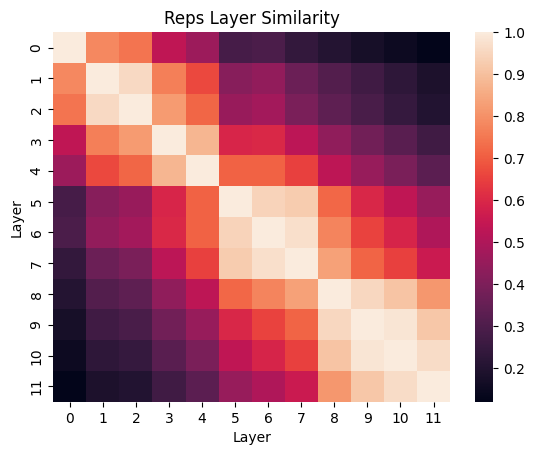

In [62]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [63]:
_,_ = adjacent_similarity_stats(val_reps_similarity)

Similarity Scores: [0.78136104, 0.95768833, 0.81958, 0.8796313, 0.70874023, 0.9415926, 0.9709361, 0.8332614, 0.95488983, 0.9845798, 0.9635165]
Number of High Similar Pairs: 9


In [64]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.85)

Similarity Scores: [0.78136104, 0.95768833, 0.81958, 0.8796313, 0.70874023, 0.9415926, 0.9709361, 0.8332614, 0.95488983, 0.9845798, 0.9635165]
Number of High Similar Pairs: 7


In [65]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.9)

Similarity Scores: [0.78136104, 0.95768833, 0.81958, 0.8796313, 0.70874023, 0.9415926, 0.9709361, 0.8332614, 0.95488983, 0.9845798, 0.9635165]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

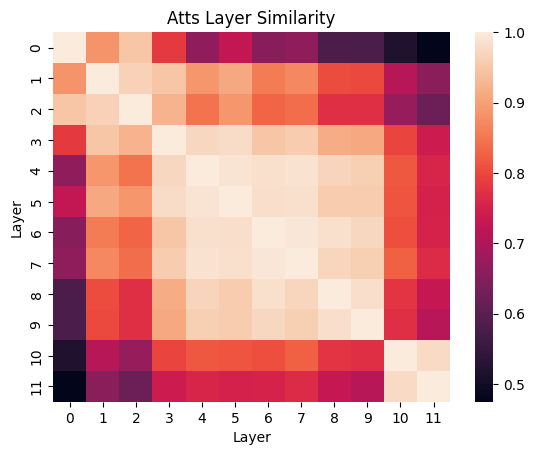

In [66]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [67]:
_,_ = adjacent_similarity_stats(val_atts_similarity)

Similarity Scores: [0.88488096, 0.9636733, 0.9235316, 0.9723023, 0.98838305, 0.9830851, 0.99197805, 0.97112596, 0.9833431, 0.7705058, 0.9754959]
Number of High Similar Pairs: 10


In [68]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.85)

Similarity Scores: [0.88488096, 0.9636733, 0.9235316, 0.9723023, 0.98838305, 0.9830851, 0.99197805, 0.97112596, 0.9833431, 0.7705058, 0.9754959]
Number of High Similar Pairs: 10


In [69]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.9)

Similarity Scores: [0.88488096, 0.9636733, 0.9235316, 0.9723023, 0.98838305, 0.9830851, 0.99197805, 0.97112596, 0.9833431, 0.7705058, 0.9754959]
Number of High Similar Pairs: 9


Text(50.722222222222214, 0.5, 'Layer')

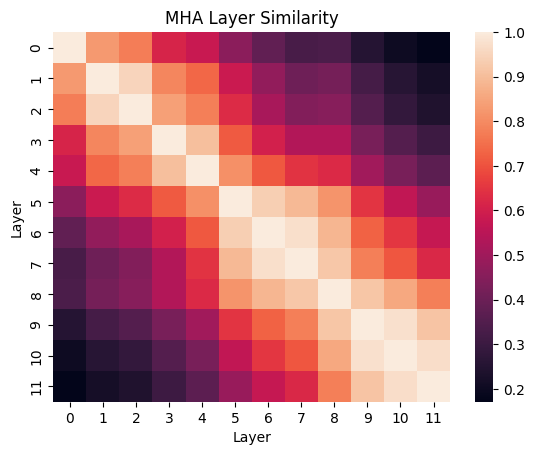

In [70]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [71]:
_,_ = adjacent_similarity_stats(val_mha_similarity)

Similarity Scores: [0.8256435, 0.948884, 0.8411281, 0.90466595, 0.81191725, 0.93838054, 0.9730123, 0.9221435, 0.91825646, 0.9764468, 0.96866584]
Number of High Similar Pairs: 11


In [72]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.85)

Similarity Scores: [0.8256435, 0.948884, 0.8411281, 0.90466595, 0.81191725, 0.93838054, 0.9730123, 0.9221435, 0.91825646, 0.9764468, 0.96866584]
Number of High Similar Pairs: 8


In [73]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.9)

Similarity Scores: [0.8256435, 0.948884, 0.8411281, 0.90466595, 0.81191725, 0.93838054, 0.9730123, 0.9221435, 0.91825646, 0.9764468, 0.96866584]
Number of High Similar Pairs: 8


Text(50.722222222222214, 0.5, 'Layer')

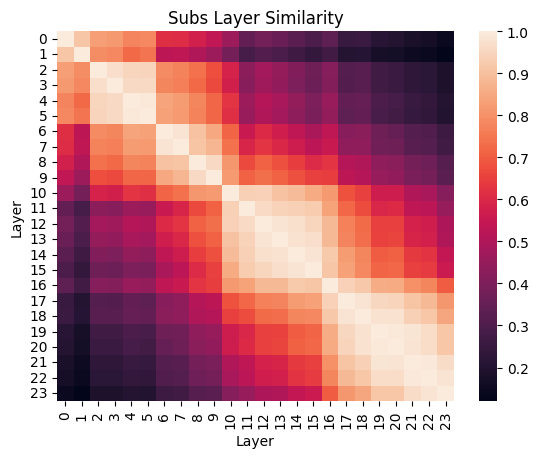

In [74]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [75]:
_,_ = adjacent_similarity_stats(val_sub_similarity)

Similarity Scores: [0.9130137, 0.79129833, 0.971799, 0.9569987, 0.99224746, 0.8318868, 0.98172843, 0.90929306, 0.95634866, 0.8208523, 0.93737227, 0.9604935, 0.9807996, 0.9768286, 0.97980636, 0.9126972, 0.9404857, 0.9799366, 0.97706664, 0.9906442, 0.9804485, 0.99350846, 0.980425]
Number of High Similar Pairs: 22


In [76]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.85)

Similarity Scores: [0.9130137, 0.79129833, 0.971799, 0.9569987, 0.99224746, 0.8318868, 0.98172843, 0.90929306, 0.95634866, 0.8208523, 0.93737227, 0.9604935, 0.9807996, 0.9768286, 0.97980636, 0.9126972, 0.9404857, 0.9799366, 0.97706664, 0.9906442, 0.9804485, 0.99350846, 0.980425]
Number of High Similar Pairs: 20


In [77]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.9)

Similarity Scores: [0.9130137, 0.79129833, 0.971799, 0.9569987, 0.99224746, 0.8318868, 0.98172843, 0.90929306, 0.95634866, 0.8208523, 0.93737227, 0.9604935, 0.9807996, 0.9768286, 0.97980636, 0.9126972, 0.9404857, 0.9799366, 0.97706664, 0.9906442, 0.9804485, 0.99350846, 0.980425]
Number of High Similar Pairs: 20


Text(50.722222222222214, 0.5, 'Layer')

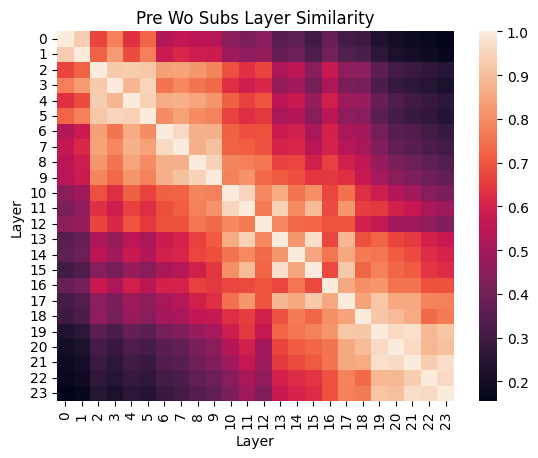

In [79]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [80]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity)

Similarity Scores: [0.93118614, 0.7228884, 0.92541754, 0.88405704, 0.9400424, 0.8008251, 0.9592374, 0.868383, 0.94617236, 0.7773158, 0.9492539, 0.7679026, 0.7913283, 0.8188827, 0.85091376, 0.67940176, 0.85446995, 0.8428898, 0.9143444, 0.9580653, 0.9609896, 0.9310118, 0.95770586]
Number of High Similar Pairs: 18


In [81]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.93118614, 0.7228884, 0.92541754, 0.88405704, 0.9400424, 0.8008251, 0.9592374, 0.868383, 0.94617236, 0.7773158, 0.9492539, 0.7679026, 0.7913283, 0.8188827, 0.85091376, 0.67940176, 0.85446995, 0.8428898, 0.9143444, 0.9580653, 0.9609896, 0.9310118, 0.95770586]
Number of High Similar Pairs: 15


In [82]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.93118614, 0.7228884, 0.92541754, 0.88405704, 0.9400424, 0.8008251, 0.9592374, 0.868383, 0.94617236, 0.7773158, 0.9492539, 0.7679026, 0.7913283, 0.8188827, 0.85091376, 0.67940176, 0.85446995, 0.8428898, 0.9143444, 0.9580653, 0.9609896, 0.9310118, 0.95770586]
Number of High Similar Pairs: 11


Text(50.722222222222214, 0.5, 'Layer')

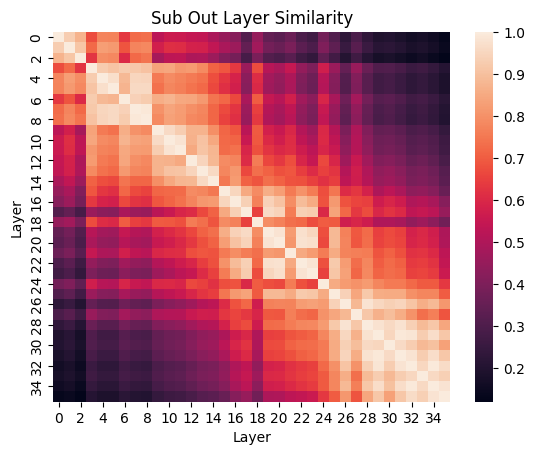

In [42]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [43]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity)

Similarity Scores: [0.93118614, 0.9130137, 0.626232, 0.92541754, 0.971799, 0.8762948, 0.9400424, 0.99224746, 0.7843553, 0.9592374, 0.98172843, 0.8495633, 0.94617236, 0.95634866, 0.75237584, 0.9492539, 0.93737227, 0.6521686, 0.7913283, 0.9807996, 0.809411, 0.85091376, 0.97980636, 0.65106446, 0.85446995, 0.9404857, 0.88033456, 0.9143444, 0.97706664, 0.9517139, 0.9609896, 0.9804485, 0.9534801, 0.95770586, 0.980425]
Number of High Similar Pairs: 29


In [44]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.85)

Similarity Scores: [0.93118614, 0.9130137, 0.626232, 0.92541754, 0.971799, 0.8762948, 0.9400424, 0.99224746, 0.7843553, 0.9592374, 0.98172843, 0.8495633, 0.94617236, 0.95634866, 0.75237584, 0.9492539, 0.93737227, 0.6521686, 0.7913283, 0.9807996, 0.809411, 0.85091376, 0.97980636, 0.65106446, 0.85446995, 0.9404857, 0.88033456, 0.9143444, 0.97706664, 0.9517139, 0.9609896, 0.9804485, 0.9534801, 0.95770586, 0.980425]
Number of High Similar Pairs: 27


In [45]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.9)

Similarity Scores: [0.93118614, 0.9130137, 0.626232, 0.92541754, 0.971799, 0.8762948, 0.9400424, 0.99224746, 0.7843553, 0.9592374, 0.98172843, 0.8495633, 0.94617236, 0.95634866, 0.75237584, 0.9492539, 0.93737227, 0.6521686, 0.7913283, 0.9807996, 0.809411, 0.85091376, 0.97980636, 0.65106446, 0.85446995, 0.9404857, 0.88033456, 0.9143444, 0.97706664, 0.9517139, 0.9609896, 0.9804485, 0.9534801, 0.95770586, 0.980425]
Number of High Similar Pairs: 23


### Using Training Data using Whole Sequence

In [44]:
reps_similarity, atts_similarity, mha_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:41<00:00,  2.80it/s]

  Reps Similarity Stats:
    Average: 0.989591
    Highest: 0.999240
    Lowest:  0.967765

  Atts Similarity Stats:
    Average: 0.944147
    Highest: 0.991294
    Lowest:  0.762895
  MHA Similarity Stats:
    Average: 0.983106
    Highest: 0.998300
    Lowest:  0.953689
  Sublayer Similarity Stats:
    Average: 0.970021
    Highest: 0.987302
    Lowest:  0.958911


In [41]:
reps_similarity, atts_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:36<00:00,  3.15it/s]

  Reps Similarity Stats:
    Average: 0.989591
    Highest: 0.999240
    Lowest:  0.967765

  Atts Similarity Stats:
    Average: 0.944147
    Highest: 0.991294
    Lowest:  0.762895
  Sublayer Similarity Stats:
    Average: 0.810862
    Highest: 0.962792
    Lowest:  0.402067


Text(50.722222222222214, 0.5, 'Layer')

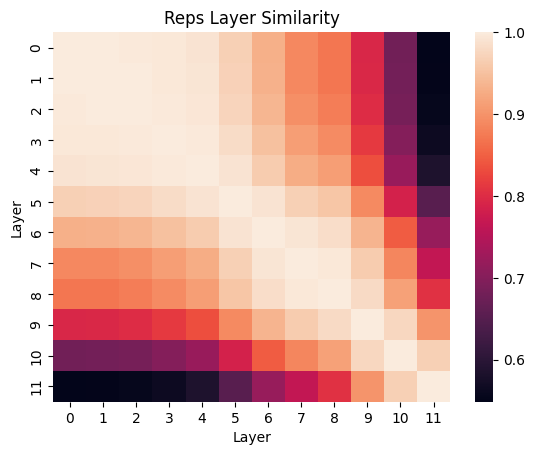

In [45]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

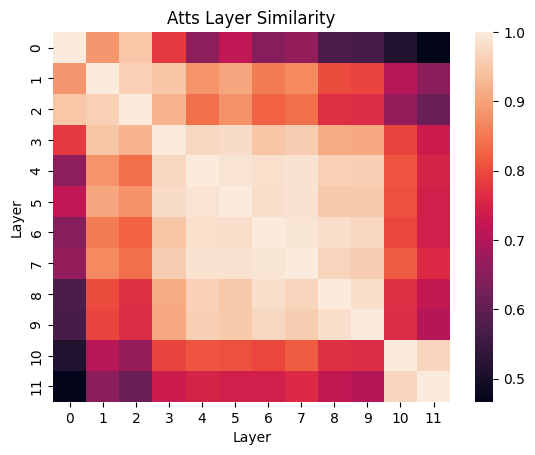

In [46]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

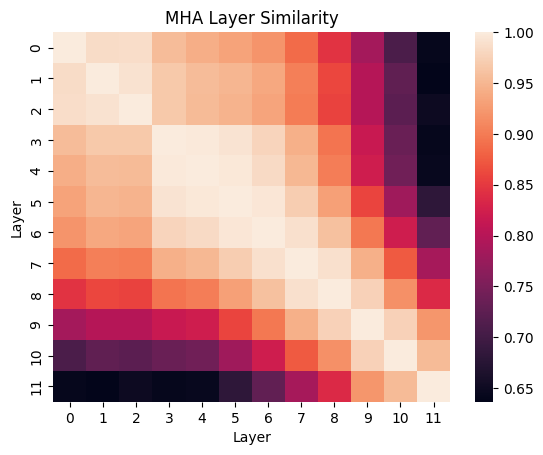

In [47]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

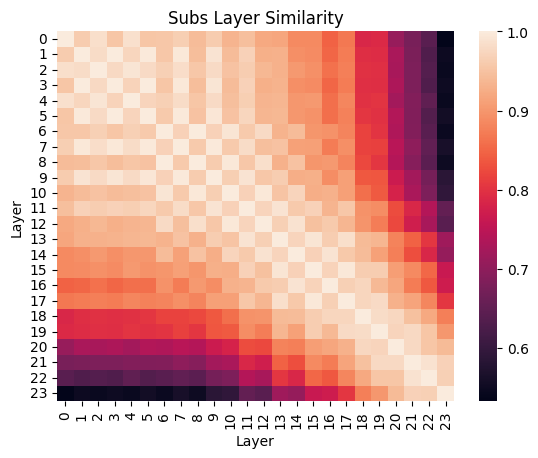

In [48]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Val Data using Whole Sequence

In [49]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 13/13 [00:04<00:00,  2.83it/s]

  Reps Similarity Stats:
    Average: 0.991503
    Highest: 0.999282
    Lowest:  0.970845

  Atts Similarity Stats:
    Average: 0.946210
    Highest: 0.991978
    Lowest:  0.770506
  MHA Similarity Stats:
    Average: 0.983591
    Highest: 0.998318
    Lowest:  0.944361
  Sublayer Similarity Stats:
    Average: 0.968635
    Highest: 0.984541
    Lowest:  0.956600


Text(50.722222222222214, 0.5, 'Layer')

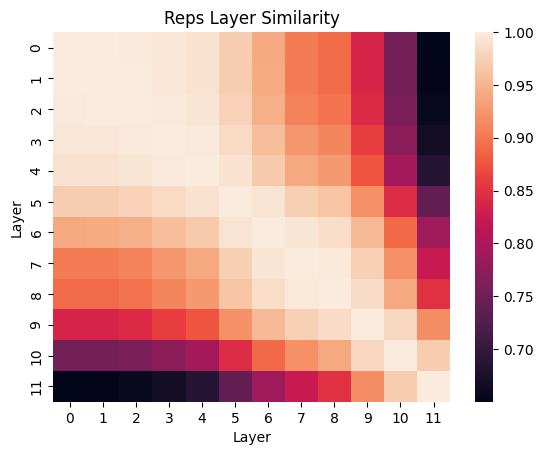

In [50]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

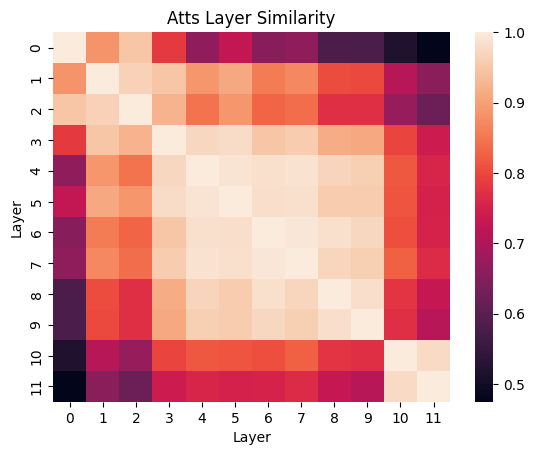

In [51]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

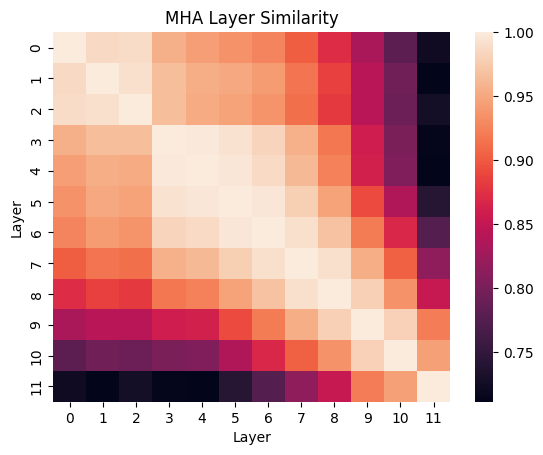

In [52]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

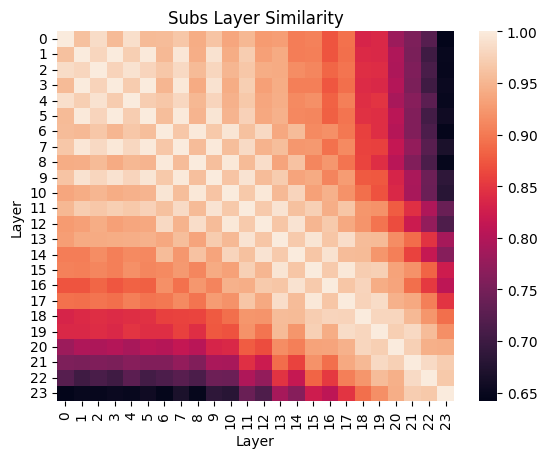

In [53]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Training Data for Heads Redundancy

In [ ]:
headsCka_eval

In [47]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 100, 100])

In [46]:
outputs.attentions['attention_head'][11].shape

torch.Size([32, 12, 100, 100])

In [38]:
from CKA import CudaCKA

In [35]:
from tqdm import tqdm

In [54]:
class TestHeadRedundancyEval:
    def __init__(self, device):
        self.cuda_cka = CudaCKA(device)
 
    def collect_selected_layer_head_matrices(self, atts, layer_indices):
        """
        atts: list of length L, each (batch, heads, seq_q, seq_k)
        layer_indices: which layers to include (e.g. [3], [0,1,2], or
                       None for all layers)
 
        Returns:
            matrices: list of (batch, seq_q, seq_k) tensors, UNFLATTENED.
                      Sentence-level CKA needs the (n, n) shape intact --
                      do not flatten these.
            labels: list of (layer_idx, head_idx) tuples, same order/length
                    as matrices. Required to interpret rows/cols of the
                    returned similarity matrix once more than one layer
                    is involved.
        """
        if layer_indices is None:
            layer_indices = [i for i in range(len(atts))]  # fixed: missing ')'
 
        matrices = []
        labels = []
        for layer_idx in layer_indices:
            layer_att = atts[layer_idx]  # (batch, heads, seq_q, seq_k)
            heads = layer_att.shape[1]
            for h in range(heads):
                matrices.append(layer_att[:, h, :, :])
                labels.append((layer_idx, h))
        return matrices, labels
 
    def _accumulate_batch(self, matrices, attention_mask, scores_accum):
        """
        Adds this batch's per-sentence CKA sums into scores_accum (in place)
        and returns how many valid sentences (n_valid >= 2) contributed.
 
        Diagonal entries are CKA(head_i, head_i) for each sentence, which
        is always exactly 1.0 -- so after normalizing by n_valid_sentences
        the diagonal stays exactly 1.0, guaranteed to be the max of every
        row/column. No special-casing needed for "same head = highest
        similarity"; it falls out of CKA's own definition as long as every
        (i, i) pair is computed the same way as every (i, j) pair below.
        """
        M = len(matrices)
        batch = matrices[0].shape[0]
        n_valid_sentences = 0
 
        with torch.no_grad():
            for b in range(batch):
                # Padding-side agnostic: works regardless of left/right padding.
                valid_idx = attention_mask[b].bool()
                n_valid = int(valid_idx.sum().item())
 
                # Guard against degenerate very-short sentences where
                # linear_CKA's variance terms can be ~0 -> NaN.
                if n_valid < 2:
                    continue
                n_valid_sentences += 1
 
                for i in range(M):
                    Ai = matrices[i][b][valid_idx][:, valid_idx]  # (n_valid, n_valid)
                    for j in range(i, M):
                        Bj = matrices[j][b][valid_idx][:, valid_idx]
                        val = self.cuda_cka.linear_CKA(Ai, Bj).detach()
                        scores_accum[i, j] += val
                        if i != j:
                            scores_accum[j, i] += val
                        # i == j case (diagonal): added once, correctly,
                        # via the scores_accum[i, j] += val line above.
 
        return n_valid_sentences
 
    def att_head_redundancy_estimate(self, model, dataloader, device,
                                      max_iter=float("Inf"), layer_indices=None,
                                      attention_mask_key="attention_mask"):
        """
        Runs sentence-level CKA head-redundancy estimation over an entire
        dataloader. Diagonal of the returned matrix is guaranteed to be
        1.0 (a head is always maximally similar to itself), so every
        row/column's max similarity is its own diagonal entry.
 
        Returns:
            scores: (M, M) numpy array, M = len(layer_indices or all)*heads
            labels: list of (layer_idx, head_idx), same order as rows/cols
        """
        model.set_use_module_grafting(False)
        model.set_use_scc_status(False)
 
        n_batch = len(dataloader)
        n_steps = min(n_batch, max_iter) if max_iter != float("Inf") else n_batch
        progress_bar = tqdm(range(n_steps), desc="CKA Sublayer Evaluation")
 
        model.eval()
 
        scores = None
        labels = None
        total_valid_sentences = 0
 
        for step, batch in enumerate(dataloader):
            if step == max_iter:
                break
 
            batch = {k: v.to(device) for k, v in batch.items()}
            attention_mask = batch[attention_mask_key]
 
            with torch.no_grad():
                output = model(**batch)
 
            atts = output.attentions["attention_head"]  # list of (batch, heads, seq_q, seq_k)
 
            matrices, labels = self.collect_selected_layer_head_matrices(atts, layer_indices)
 
            if scores is None:
                M = len(matrices)
                scores = torch.zeros(M, M, device=matrices[0].device)
 
            n_valid = self._accumulate_batch(matrices, attention_mask, scores)
            total_valid_sentences += n_valid
 
            progress_bar.update(1)
 
        if total_valid_sentences == 0:
            scores.fill_(float("nan"))
        else:
            scores = scores / total_valid_sentences
 
        # Sanity: diagonal should be (numerically) 1.0 -- confirms the
        # "same head = highest similarity" property holds by construction.
        return scores.cpu().numpy(), labels

In [55]:
test = TestHeadRedundancyEval(device)

In [57]:
scores, labels = test.att_head_redundancy_estimate(model, train_dataloader, device, layer_indices=[10, 11], max_iter=5)

CKA Sublayer Evaluation: 100%|██████████| 5/5 [00:13<00:00,  2.63s/it]


In [43]:
for batch in train_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    attention_mask = batch['attention_mask']
    with torch.no_grad():
        output = model(**batch)
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 77]),
 'token_type_ids': torch.Size([32, 77]),
 'attention_mask': torch.Size([32, 77])}

In [44]:
len(outputs.attentions['attention_head'])

12

In [45]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 100, 100])

In [47]:
matrices, labels = test.collect_selected_layer_head_matrices(outputs.attentions['attention_head'], [0, 1])

In [48]:
labels

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 9),
 (0, 10),
 (0, 11),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (1, 7),
 (1, 8),
 (1, 9),
 (1, 10),
 (1, 11)]

In [50]:
len(matrices)

24

In [52]:
matrices[0].shape

torch.Size([32, 100, 100])

In [58]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Heads')

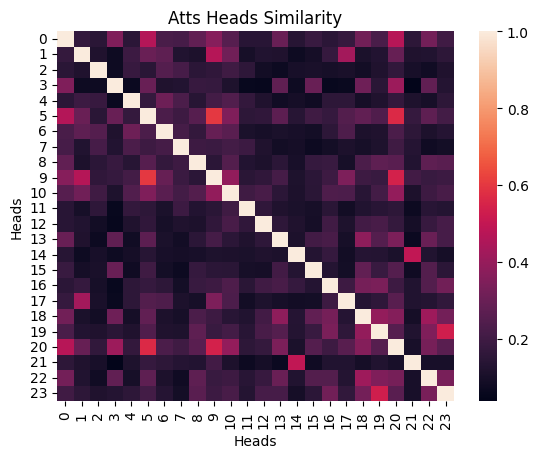

In [59]:
title = "Atts Heads Similarity"
plt.title(title)
sn.heatmap(data = scores)
plt.xlabel("Heads")
plt.ylabel("Heads")

# 6. Sensitivity Score Analysis

In [36]:
from structure_prune_helper import register_importance_masks

In [37]:
register_importance_masks(
    model, device, register_pre_wo_layer=True, register_mha=True, register_mlp=True, register_mha_layer=True, register_mlp_layer=True
)

  Layer 0: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 1: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 2: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 3: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 4: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 5: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 6: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 7: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 8: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 9: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 10: Register

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [38]:
from structure_prune_helper import compute_layer_importance_scores

In [39]:
pre_wo_importance, mha_importance, ffn_importance, head_importance, neuron_importance, sublayer_importance =compute_layer_importance_scores(
    model, train_dataloader, device, max_batches=115,
    compute_mha=True, compute_ffn=True, compute_heads=True,
    compute_neurons=True, compute_pre_wo=True,
    display_separate=True, display_combined=True, display_pruning_order=True,
)

Computing importance (pre-WO layer, MHA layer, FFN layer, heads, neurons): 100%|██████████| 115/115 [00:12<00:00,  9.56it/s]


Layer Importance Summary (separate):
          Layer  Pre-WO(layer)     MHA(layer)     FFN(layer)    Heads(mean)  Neurons(mean)
  ------------------------------------------------------------------------------------------
  0                     1.0000         0.7063         1.0000         0.0000         0.0000
  1                     0.7392         0.9218         0.4006         0.0000         0.0000
  2                     0.7710         0.5798         0.8570         0.0000         0.0000
  3                     0.7850         0.5221         0.5792         0.0000         0.0000
  4                     0.3555         0.3997         0.9679         0.0000         0.0000
  5                     0.9896         1.0000         0.6162         0.0000         0.0000
  6                     0.2678         0.2935         0.4970         0.0000         0.0000
  7                     0.2148         0.1831         0.2741         0.0000         0.0000
  8                     0.4247         0.3112     

In [40]:
pre_wo_importance

array([1.        , 0.7392156 , 0.7709775 , 0.7850319 , 0.35546938,
       0.9896459 , 0.26779464, 0.21475871, 0.42471576, 0.17042425,
       0.17188814, 0.10218327], dtype=float32)

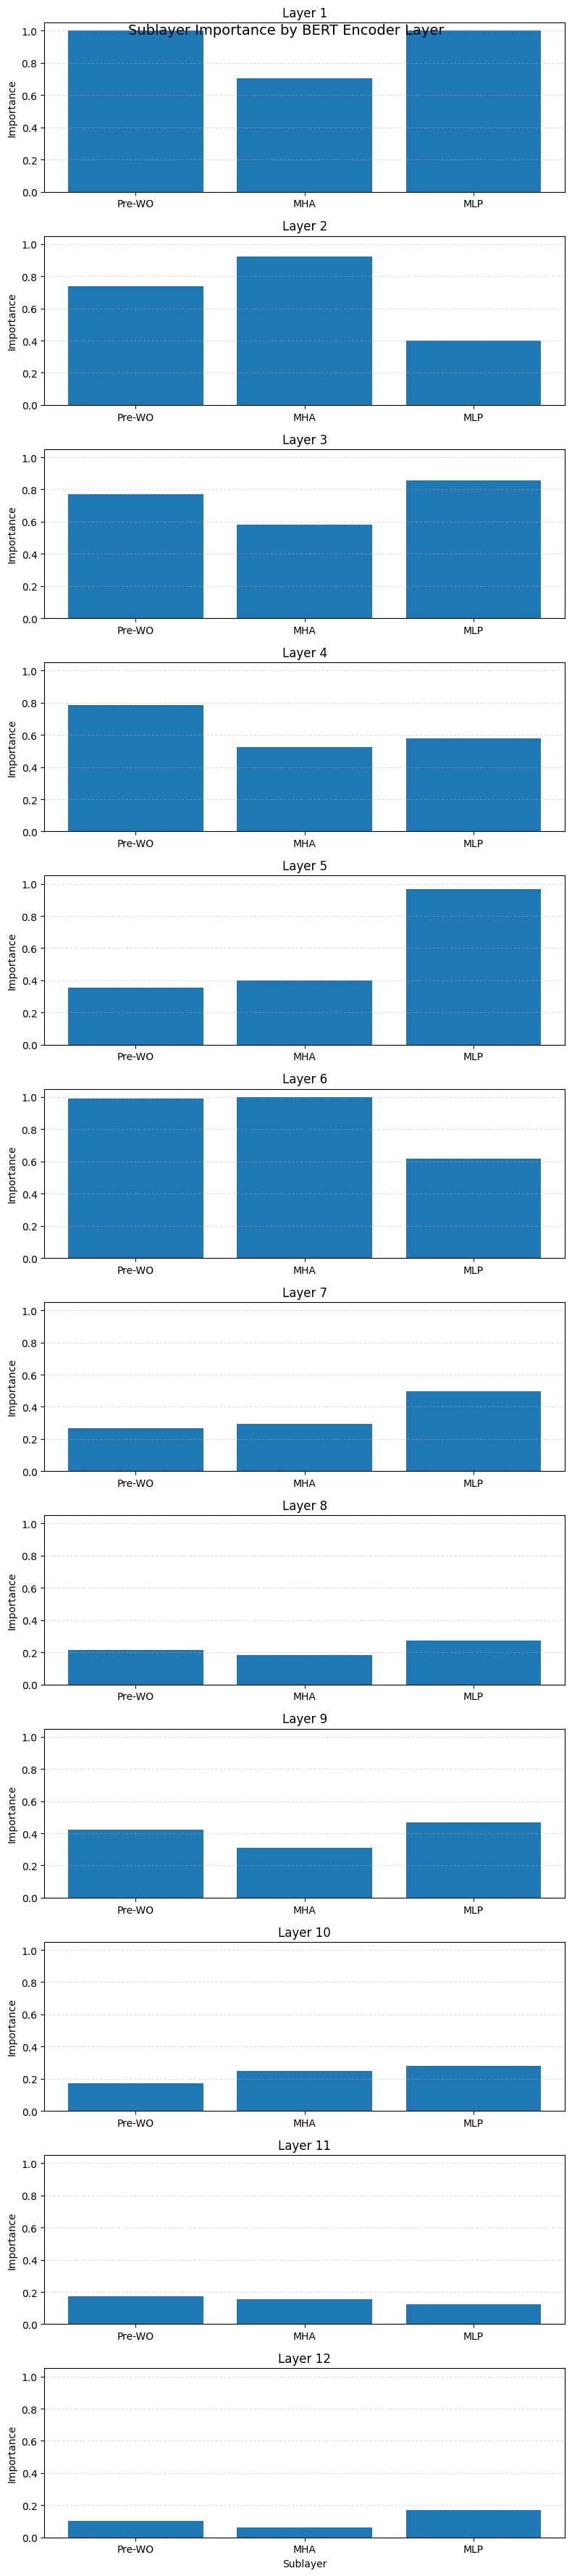

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Importance scores returned by compute_layer_importance_scores()
# pre_wo_importance, mha_importance, ffn_importance

n_layers = len(pre_wo_importance)

fig, axes = plt.subplots(
    n_layers, 1,
    figsize=(8, 3 * n_layers),
    sharey=True
)

# Handle the case of a model with only one layer
if n_layers == 1:
    axes = [axes]

labels = ["Pre-WO", "MHA", "MLP"]

for layer_idx, ax in enumerate(axes):
    scores = [
        pre_wo_importance[layer_idx],
        mha_importance[layer_idx],
        ffn_importance[layer_idx],
    ]

    ax.bar(labels, scores)
    ax.set_title(f"Layer {layer_idx + 1}")
    ax.set_ylabel("Importance")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Sublayer")
fig.suptitle("Sublayer Importance by BERT Encoder Layer", fontsize=14)
plt.tight_layout()
plt.show()

### Using Training Data on CLS Token only

In [39]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:51<00:00,  2.23it/s]

  Reps Similarity Stats:
    Average: 0.899587
    Highest: 0.993594
    Lowest:  0.723103

  Atts Similarity Stats:
    Average: 0.944064
    Highest: 0.991232
    Lowest:  0.760821
  MHA Similarity Stats:
    Average: 0.916322
    Highest: 0.988968
    Lowest:  0.809322
  Pre Wo Similarity Stats:
    Average: 0.828560
    Highest: 0.946645
    Lowest:  0.644238
  Sublayer Similarity Stats:
    Average: 0.948331
    Highest: 0.996554
    Lowest:  0.788115
  Pre Wo Sublayer Similarity Stats:
    Average: 0.880918
    Highest: 0.974673
    Lowest:  0.706310


In [40]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:38<00:00,  3.01it/s]

  Sub Out Similarity Stats:
    Average: 0.904148
    Highest: 0.994790
    Lowest:  0.616531


In [41]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

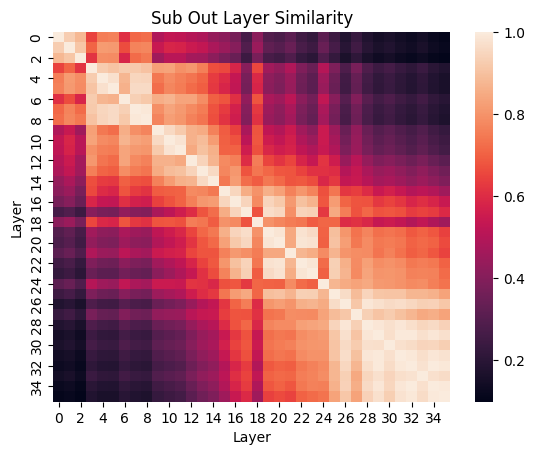

In [42]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [44]:
sub_out_similarity.shape 

(36, 36)

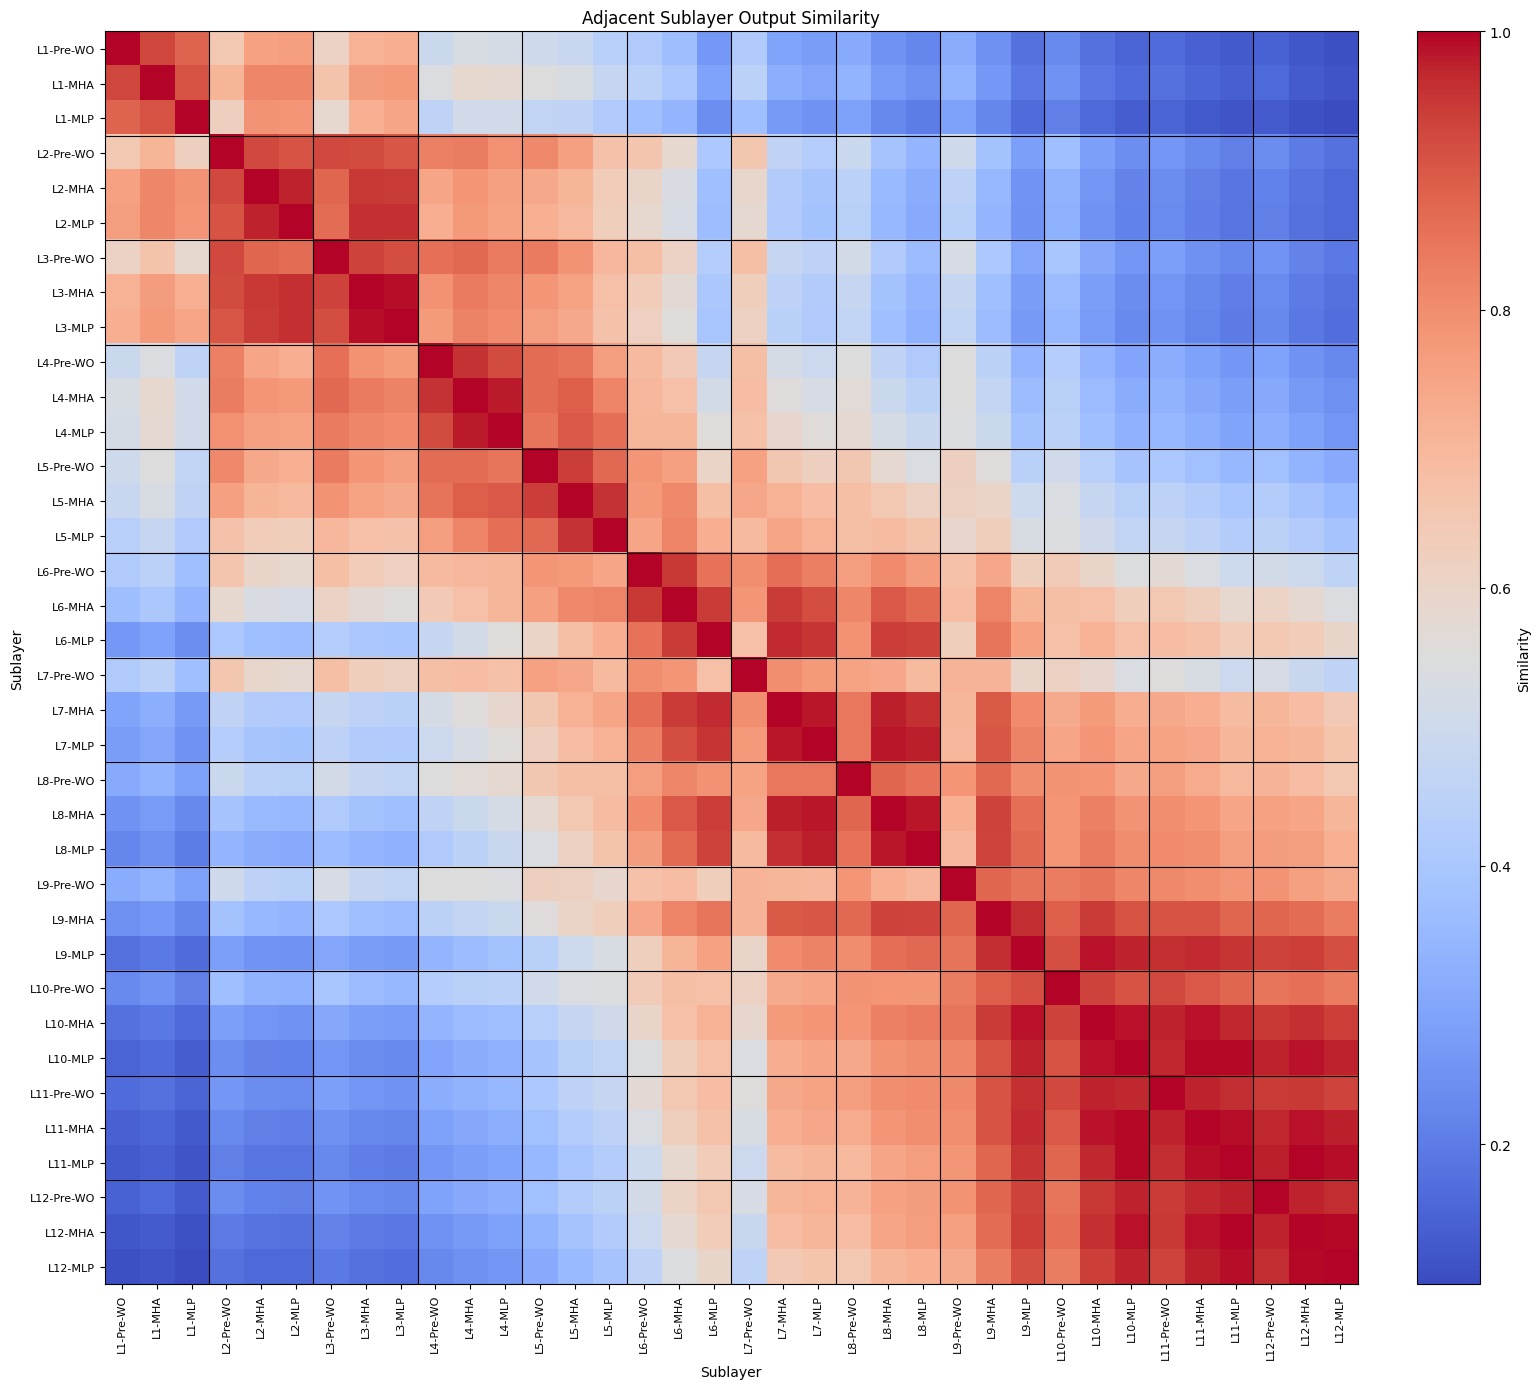

In [45]:
import matplotlib.pyplot as plt
import numpy as np

# sub_out_similarity: (36, 36)
n_layers = 12
sublayers = ["Pre-WO", "MHA", "MLP"]

labels = [
    f"L{layer + 1}-{sub}"
    for layer in range(n_layers)
    for sub in sublayers
]

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    sub_out_similarity,
    cmap="coolwarm",
    interpolation="nearest",
    aspect="equal"
)

# Label every sublayer
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

# Add boundaries between encoder layers
for boundary in range(3, n_layers * 3, 3):
    ax.axhline(boundary - 0.5, color="black", linewidth=0.8)
    ax.axvline(boundary - 0.5, color="black", linewidth=0.8)

# Color scale
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Similarity")

ax.set_title("Adjacent Sublayer Output Similarity")
ax.set_xlabel("Sublayer")
ax.set_ylabel("Sublayer")

plt.tight_layout()
plt.show()